<a href="https://colab.research.google.com/github/xomila/MySpace-resurrection/blob/main/mnist_digit_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(x_train.shape, y_train.shape)  # (60000, 28, 28) (60000,)
print(x_test.shape, y_test.shape)    # (10000, 28, 28) (10000,)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


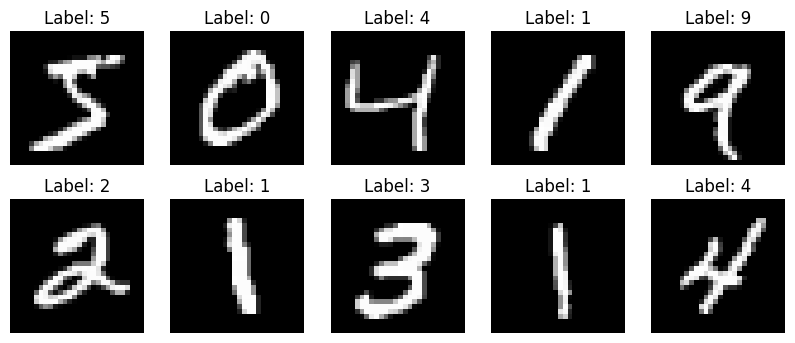

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.show()

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, -1)  # (60000, 28, 28, 1)
x_test = np.expand_dims(x_test, -1)

In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [7]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 83ms/step - accuracy: 0.8896 - loss: 0.3620 - val_accuracy: 0.9782 - val_loss: 0.0820
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 83ms/step - accuracy: 0.9664 - loss: 0.1103 - val_accuracy: 0.9833 - val_loss: 0.0592
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 34s 81ms/step - accuracy: 0.9743 - loss: 0.0838 - val_accuracy: 0.9875 - val_loss: 0.0474
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 83ms/step - accuracy: 0.9782 - loss: 0.0711 - val_accuracy: 0.9868 - val_loss: 0.0437
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 84ms/step - accuracy: 0.9809 - loss: 0.0614 - val_accuracy: 0.9893 - val_loss: 0.0357
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 34s 80ms/step - accuracy: 0.9831 - loss: 0.0536 - val_accuracy: 0.9902 - val_loss: 0.0379
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 35s 82ms/step - accuracy: 0.9837 - loss: 0.0510 - val_accuracy: 0.9907 - val_loss: 0.0336
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - accuracy: 0.9853 - loss: 0.0467 - 

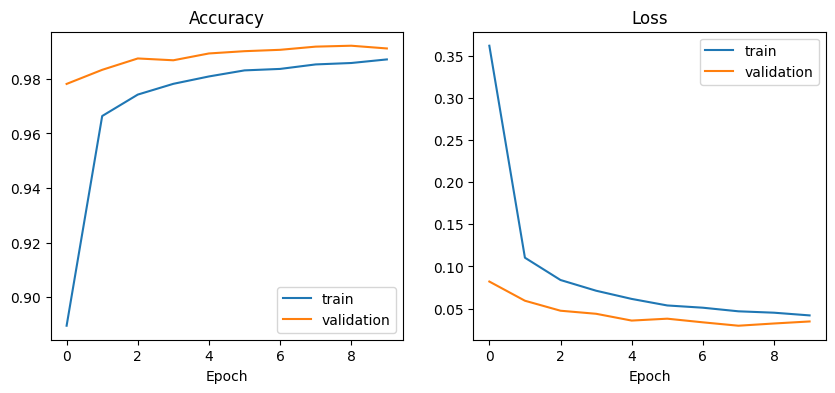

In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()

plt.show()

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

Test accuracy: 0.9893


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


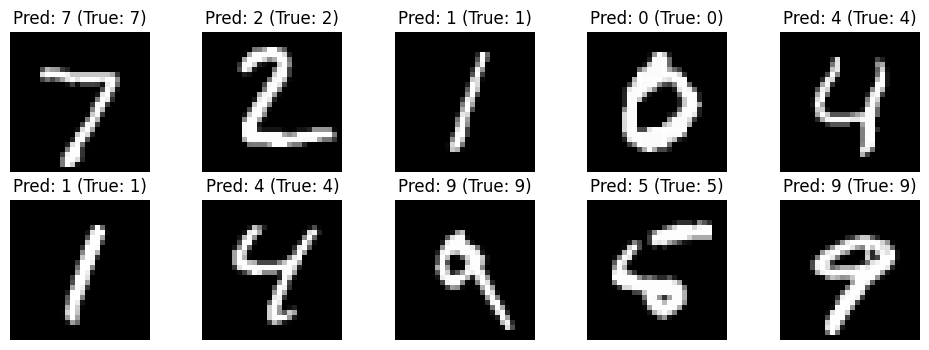

In [10]:
preds = model.predict(x_test[:10])

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {np.argmax(preds[i])} (True: {y_test[i]})")
    plt.axis("off")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step


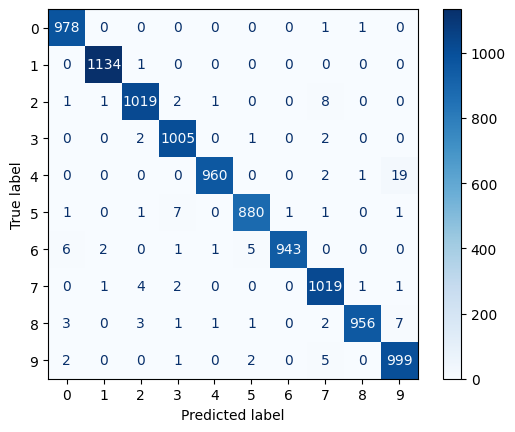

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(model.predict(x_test), axis=1)
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.show()

In [24]:
from google.colab import files

uploaded = files.upload()
fname = list(uploaded.keys())[0]
print("Uploaded:", fname)

Saving 2026_11_05_01s_Kleki.png to 2026_11_05_01s_Kleki.png
Uploaded: 2026_11_05_01s_Kleki.png


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Predicted digit: 6
Confidence: 90.28%


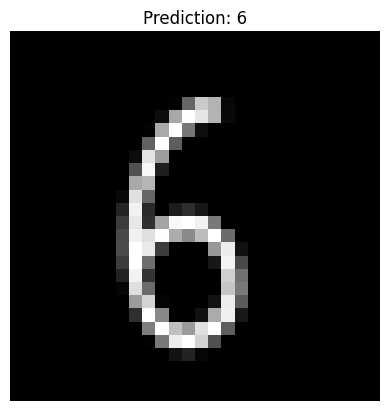

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

img = Image.open(fname).convert("L")
img = img.resize((28, 28))

arr = np.array(img).astype("float32") / 255.0
arr = arr.reshape(1, 28, 28, 1)

pred = model.predict(arr)
digit = np.argmax(pred)

print("Predicted digit:", digit)
print("Confidence:", f"{pred.max():.2%}")

plt.imshow(arr.squeeze(), cmap="gray")
plt.title(f"Prediction: {digit}")
plt.axis("off")
plt.show()

In [26]:
from google.colab import files

uploaded = files.upload()
fname = list(uploaded.keys())[0]
print("Uploaded:", fname)

Saving 2026_11_05_01t_Kleki.png to 2026_11_05_01t_Kleki.png
Uploaded: 2026_11_05_01t_Kleki.png


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Predicted digit: 1
Confidence: 93.83%


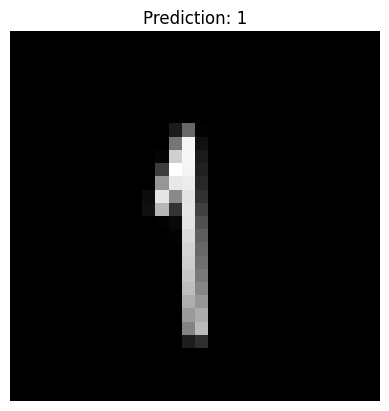

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

img = Image.open(fname).convert("L")
img = img.resize((28, 28))

arr = np.array(img).astype("float32") / 255.0
arr = arr.reshape(1, 28, 28, 1)

pred = model.predict(arr)
digit = np.argmax(pred)

print("Predicted digit:", digit)
print("Confidence:", f"{pred.max():.2%}")

plt.imshow(arr.squeeze(), cmap="gray")
plt.title(f"Prediction: {digit}")
plt.axis("off")
plt.show()